## 04 Analysis of Results in Tarifverbund Schwyz

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os

stop_places = gpd.read_file(
    '../data/stop-places-schweiz/stop-places-schweiz-with-buffers.gpkg', 
    layer = 'stop_buffers',
)

stop_places.head()

,Name,Nummer,buffer_timeseries,geometry
0,"Winterthur, Wylandbrücke",8591016,"[{""time"": ""2026-04-15T03:09:00Z"", ""incoming_li...",POINT (2696613 1261277)
1,"Visp, Lonzawerke",8501717,"[{""time"": ""2026-04-15T02:40:00Z"", ""incoming_li...",POINT (2634465 1127161)
2,"Obersaxen, Tobel",8574998,NO TRANSFERS,POINT (2726543 1178524)
3,Le Prese,8509364,"[{""time"": ""2026-04-15T04:27:00Z"", ""incoming_li...",POINT (2803370 1130052)
4,"Kippel, Dorf",8507761,NO TRANSFERS,POINT (2625504 1138634)


Total Stops: 28919
Stops without Service: 5281
Stops without Transfer: 14842
Stops with Possible Transfers: 8796


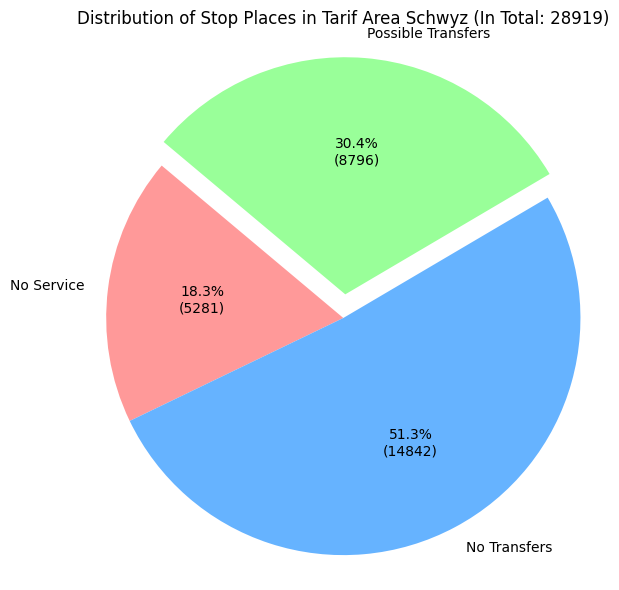

In [2]:
# Stats for stops without service, transfers and stops with possible transfers
total_stops = len(stop_places)
stops_without_service = len(stop_places[stop_places['buffer_timeseries']=='NO SERVICE'])
stops_without_transfer = len(stop_places[stop_places['buffer_timeseries']=='NO TRANSFERS'])
stops_with_transfers = total_stops - stops_without_service - stops_without_transfer

# Print the results
print(f"Total Stops: {total_stops}")
print(f"Stops without Service: {stops_without_service}")
print(f"Stops without Transfer: {stops_without_transfer}")
print(f"Stops with Possible Transfers: {stops_with_transfers}")

# Function to format the labels to show both count and percentage
def label_format(pct, allvals):
    absolute = int(round(pct/100.* np.sum(allvals)))
    return f"{pct:.1f}%\n({absolute:d})"

# Create the pie chart
plt.figure(figsize=(6,6))
plt.pie([stops_without_service, stops_without_transfer, stops_with_transfers], 
        explode=(0, 0, 0.1), 
        labels=['No Service', 'No Transfers', 'Possible Transfers'], 
        colors=['#ff9999','#66b3ff','#99ff99'], 
        autopct=lambda pct: label_format(pct, [stops_without_service, stops_without_transfer, stops_with_transfers]), 
        startangle=140)

plt.title(f'Distribution of Stop Places in Tarif Area Schwyz (In Total: {total_stops})')
plt.axis('equal')
plt.tight_layout()
# plt.savefig('stops_statistics_pie_chart.png')
plt.show()

In [3]:
stop_places_active = stop_places[
    (stop_places['buffer_timeseries'] != 'NO SERVICE') & 
    (stop_places['buffer_timeseries'] != 'NO TRANSFERS')
].copy()
stop_places_active.reset_index(drop=True, inplace=True)

In [4]:
stop_places_active['buffer_timeseries'] = stop_places_active['buffer_timeseries'].apply(json.loads)
df_long = stop_places_active.explode('buffer_timeseries')
df_unpacked = pd.concat([
    df_long.drop(columns=['buffer_timeseries']).reset_index(drop=True),
    pd.json_normalize(df_long['buffer_timeseries']).reset_index(drop=True)
], axis=1)
df_unpacked['buffer'] = df_unpacked['buffer'] / 60

df_unpacked['time'] = pd.to_datetime(df_unpacked['time'])
df_unpacked['buffer'] = pd.to_numeric(df_unpacked['buffer'])

In [5]:
bins = [0, 1, 3, 5, 10, 20, float('inf')]
labels = ['<1m', '1-3m', '3-5m', '5-10m', '10-20m', '20m+']
df_unpacked['buffer_category'] = pd.cut(df_unpacked['buffer'], bins=bins, labels=labels, include_lowest=True)

# create per-stop summary table
# This counts how many times each stop falls into each buffer category
stop_histogram = pd.crosstab(
    index=[df_unpacked['Nummer'], df_unpacked['Name'], df_unpacked['geometry']], 
    columns=df_unpacked['buffer_category']
)

# add original buffer_timeseries per stop to keep detailed transfer timeline in output
buffer_timeseries_by_stop = (
    stop_places_active[['Nummer', 'Name', 'buffer_timeseries']]
    .drop_duplicates(subset=['Nummer', 'Name'])
)
stop_histogram = (
    stop_histogram
    .reset_index()
    .merge(buffer_timeseries_by_stop, on=['Nummer', 'Name'], how='left')
    .set_index(['Nummer', 'Name', 'geometry'])
)
stop_histogram['buffer_timeseries'] = stop_histogram['buffer_timeseries'].apply(
    lambda value: json.dumps(value) if isinstance(value, (list, dict)) else value
)

stop_histogram.sort_values(by='<1m', ascending=False, inplace=True)
stop_histogram

,,,<1m,1-3m,3-5m,5-10m,10-20m,20m+,buffer_timeseries
Nummer,Name,geometry,,,,,,,
8587057,"Genève, gare Cornavin",POINT (2499967 1118415),2551,17,6,8,3,4,"[{""time"": ""2026-04-15T00:02:00Z"", ""incoming_li..."
8587387,"Genève, Bel-Air",POINT (2500005 1117858),2510,57,8,1,0,1,"[{""time"": ""2026-04-15T02:19:00Z"", ""incoming_li..."
8589801,"Luzern, Kantonalbank",POINT (2665926 1211234),2342,36,1,1,2,2,"[{""time"": ""2026-04-15T02:37:00Z"", ""incoming_li..."
8576646,"Bern, Bahnhof",POINT (2600120 1199669),2169,45,3,10,2,0,"[{""time"": ""2026-04-15T03:06:00Z"", ""incoming_li..."
8588780,"Basel, Schifflände",POINT (2611179 1267620),2130,25,3,6,2,1,"[{""time"": ""2026-04-15T02:40:00Z"", ""incoming_li..."
...,...,...,...,...,...,...,...,...,...
8582619,"Lyss, Bahnhof Ost",POINT (2590061 1213863),0,0,14,2,9,31,"[{""time"": ""2026-04-15T04:16:00Z"", ""incoming_li..."
8582634,"Einsiedeln, Lärchenweg",POINT (2699727 1221118),0,6,4,0,2,28,"[{""time"": ""2026-04-15T03:46:00Z"", ""incoming_li..."
8582639,"Martigny, Place de Rome",POINT (2571949 1105988),0,0,1,1,4,42,"[{""time"": ""2026-04-15T03:49:00Z"", ""incoming_li..."


In [6]:
# Calculate Average and Median buffer for every stop
stop_performance = df_unpacked.groupby(['Nummer', 'Name', 'geometry'])['buffer'].agg(['mean', 'median', 'max', 'count'])

# Calculate Rush Hour performance per stop
rush_hour_mask = df_unpacked['time'].dt.hour.isin([7, 8, 16, 17])
stop_rush_performance = df_unpacked[rush_hour_mask].groupby(['Nummer', 'Name', 'geometry'])['buffer'].mean().rename('rush_hour_mean')

# Combine them into one master "Stop Analytics" dataframe
stop_analytics = stop_performance.join(stop_rush_performance)

stop_analytics

,,,mean,median,max,count,rush_hour_mean
Nummer,Name,geometry,,,,,
8101237,Forst (FL) Hilti,POINT (2757832 1227693),248.428571,55.0,639.0,21,155.000000
8101242,Nendeln,POINT (2759353 1229868),258.400000,142.0,638.0,20,179.200000
8101243,Schaan-Vaduz,POINT (2756906 1226260),246.428571,52.0,636.0,21,152.500000
8500005,"Camischolas, via Alpsu/Strem",POINT (2701466 1170683),334.870968,325.0,760.0,31,408.000000
8500010,Basel SBB,POINT (2611363 1266310),5.944444,1.0,233.0,468,2.558824
...,...,...,...,...,...,...,...
8596090,"Aigle, Les Glariers",POINT (2563730 1130027),8.567376,4.0,44.0,141,9.068966
8596100,"Bassersdorf, Sportanlage",POINT (2688403 1255512),156.796460,93.0,496.0,113,383.500000
8596101,"Le Locle, gare/centre ville",POINT (2547453 1212040),6.196970,2.0,483.0,198,3.739130


In [7]:
# Create an hourly map for each stop
# Rows = Stops, Columns = Hours of the day
stop_hourly_map = df_unpacked.pivot_table(
    index='Name', 
    columns=df_unpacked['time'].dt.hour, 
    values='buffer', 
    aggfunc='mean'
)

stop_hourly_map

time,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Name,,,,,,,,,,,,,,,,,,,,,
Aadorf,NaN,NaN,31.0,27.000000,26.500000,26.500000,26.500000,26.500000,26.500000,26.500000,...,26.500000,26.500000,26.500000,26.500000,26.500000,26.000000,NaN,NaN,NaN,NaN
Aarau,NaN,NaN,16.0,1.800000,1.240000,1.269231,1.200000,1.200000,1.200000,1.200000,...,1.200000,1.230769,1.200000,1.200000,1.200000,1.200000,1.200000,1.200000,15.882353,NaN
"Aarau, Aarepark",NaN,NaN,NaN,3.000000,1.600000,1.777778,1.937500,2.000000,2.000000,2.000000,...,1.777778,1.777778,1.970588,2.000000,2.000000,2.000000,2.000000,2.347826,10.888889,NaN
"Aarau, Amthaus",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,3.333333,3.461538,3.461538,3.461538,4.280000,NaN,NaN
"Aarau, Bahnhof",NaN,NaN,NaN,2.071429,2.115385,1.951613,2.218182,2.690476,2.756098,2.756098,...,1.586207,1.600000,1.709091,2.690476,2.315789,2.342857,2.457143,3.156250,11.076923,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Zürich, Zwielplatz",NaN,NaN,6.0,3.166667,1.903226,1.607143,1.655172,1.428571,0.875000,0.875000,...,1.600000,1.500000,1.857143,0.935484,2.400000,2.750000,3.863636,3.733333,NaN,NaN
"Zürich, Zwinglihaus",NaN,NaN,13.0,2.842105,1.230769,1.444444,1.416667,1.562500,1.625000,1.625000,...,1.594595,1.666667,1.571429,1.029412,2.344828,3.250000,3.565217,5.882353,NaN,NaN
"Zürich, Zypressenstrasse",NaN,NaN,17.5,1.954545,1.828571,2.266667,2.428571,2.129032,2.428571,2.428571,...,2.259259,2.428571,1.843750,2.379310,2.241379,2.500000,3.090909,2.500000,4.588235,72.666667


In [8]:
# Export stop_histogram to GeoJSON in Web Mercator
stop_histogram_gdf = gpd.GeoDataFrame(stop_histogram.reset_index(), geometry='geometry')
os.makedirs('../data/output', exist_ok=True)
stop_histogram_gdf.to_crs('EPSG:4326').to_file('../data/output/stop_histogram_schweiz.geojson', driver='GeoJSON')
print("Exported stop_histogram_schweiz.geojson to ../data/output/ in Web Mercator (EPSG:4326)")

Exported stop_histogram_schweiz.geojson to ../data/output/ in Web Mercator (EPSG:4326)
